# Shot metrics

One calibrated clip. Landmarks in `trajectories/game1_landmarks.yaml` fix the camera. The efficient tracker produces the image track, and a smoothed court-plane track cuts hits and bounces.

`RULES` in the next cell is the trajectory model. The fit stores those rules on each shot, and the printed path is that stored model played forward. Change a value, then re-run from that cell.

`GAME` and `CLIP` default to the clip that contains the calibration frame. Speed is in mph. Heights and clearance are meters. A negative clearance would hit the tape.


In [6]:
import csv
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "base_akf.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
from tracking.efficient.model import EfficientTracker
from tracking.ssm.base_akf.model import rts_smooth
from trajectories.ballistic import FPS, FlightRules, ShotInput, fit_shots
from trajectories.camera import (
    court_from_image,
    estimate_camera,
    estimate_homography,
    reprojection_rmse,
    validate_court,
)
from trajectories.court import HALF_DOUBLES, HALF_LENGTH, load_landmarks, marked, segments
from trajectories.metrics import measure_shot
from trajectories.segment import detect_cuts, iter_flights

# The model. Printed trajectories use the rules stored on the fit.
RULES = FlightRules(
    drag_k=0.022,        # 1/m. 0 is gravity only.
    pin_bounce_z=True,  # force Z at the bounce to 0.
    contact_z_min=0.2,
    contact_z_max=3.0,  # serve contact. Later hits use hit_z_max.
    hit_z_max=2.0,
    clear_net=True,
    lock_bounce_heading=True,
    bounce_keep=0.05,   # hard floor on horizontal speed kept through the bounce.
    bounce_keep_low=0.40,
    bounce_keep_high=0.80,  # penalize a keep outside this band.
)

LANDMARKS = ROOT / "trajectories" / "game1_landmarks.yaml"
with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    dataset = (ROOT / dataset).resolve()

# None follows the calibration frame. Set both to open some other clip.
GAME = None
CLIP = None


## Camera

The homography maps the ground plane. The pinhole camera is what puts the ball, which is off the ground, back into the image. This raises, and the cells below do not run, when the RMS error is above 20 cm or a measured length is off by more than 3%.


In [7]:
landmarks, meta = load_landmarks(LANDMARKS)
ready = marked(landmarks)
ground = [item for item in ready if abs(float(item.world[2])) <= 1e-8]
if meta["frame"] is None or len(ground) < 4:
    raise RuntimeError(
        "Fill frame and at least 4 ground-point image pixels in "
        "trajectories/game1_landmarks.yaml. "
        f"frame={meta['frame']!r}, marked ground points={len(ground)}."
    )
if (SRC_W, SRC_H) != tuple(meta["image_size"]):
    raise RuntimeError(
        f"landmark image_size {meta['image_size']} does not match the tracker "
        f"{SRC_W}x{SRC_H}"
    )
width, height = meta["image_size"]
frame_path = dataset / meta["frame"]

bgr = cv2.imread(str(frame_path), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(frame_path)
if bgr.shape[1] != width or bgr.shape[0] != height:
    raise RuntimeError(
        f"{frame_path.name} is {bgr.shape[1]}x{bgr.shape[0]}, "
        f"landmarks are marked for {width}x{height}"
    )

world = np.stack([item.world for item in ready])
uv = np.stack([item.image for item in ready])
on_ground = np.abs(world[:, 2]) <= 1e-8
H = estimate_homography(world[on_ground, :2], uv[on_ground])
camera = estimate_camera(world, uv, (width, height), homography=H)
center = camera.center()
print(
    f"focal {camera.focal:.0f} px  "
    f"center {np.array2string(center, precision=2)} m  "
    f"landmark reprojection {reprojection_rmse(camera, world, uv):.2f} px"
)
if center[2] <= 0.5:
    print("camera is under the court")
print(validate_court(ready, H))


focal 1828 px  center [ 0.09 32.69  8.52] m  landmark reprojection 1.92 px
court RMS 0.115 m
  doubles_near_left: 0.024 m
  doubles_near_right: 0.039 m
  doubles_far_left: 0.205 m
  doubles_far_right: 0.057 m
  singles_near_left: 0.043 m
  singles_near_right: 0.030 m
  singles_far_left: 0.188 m
  singles_far_right: 0.078 m
  service_near_left: 0.025 m
  service_near_right: 0.101 m
  service_far_left: 0.115 m
  service_far_right: 0.216 m
  baseline_near: 0.077 m
  baseline_far: 0.129 m
  service_near: 0.038 m
  service_far: 0.160 m
  baseline length: 23.886 m (expected 23.77 m)
  doubles width: 11.019 m (expected 10.97 m)
  service depth: 6.337 m (expected 6.40 m)


## Track

The clip that contains the calibration frame, unless `GAME` and `CLIP` are set. Shots and bounces use the smoothed track. The fit uses the measurements.


In [8]:
rel = Path(meta["frame"])
game = GAME or rel.parts[0]
clip = CLIP or rel.parts[1]


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = dataset / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "status": int(row["status"] or 0),
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    out_w, out_h = tracker.out_w, tracker.out_h
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
tracker.rules.start_at_uncertainty = True

frames = load_clip(game, clip)
grays = [read_gray(frame["path"]) for frame in frames]
rgbs = [read_rgb(frame["path"]) for frame in frames]
steps = tracker.find_positions(grays, rgbs)

n = len(frames)
meas = np.full((n, 2), np.nan)
r_std = np.full(n, np.nan)
state = np.full((n, 4), np.nan)
cov = np.zeros((n, 4, 4))
pred_state = np.full((n, 4), np.nan)
pred_cov = np.zeros((n, 4, 4))
status = np.array([frame["status"] for frame in frames], dtype=np.int64)
for i, step in enumerate(steps):
    if step is None:
        continue
    state[i] = step["state"]
    cov[i] = step["cov"]
    if step["pred_state"] is not None:
        pred_state[i] = step["pred_state"]
        pred_cov[i] = step["pred_cov"]
    if step["used"] and step["z"] is not None:
        meas[i] = step["z"]
        r_std[i] = step["r_std"]
print(
    f"{game}/{clip}  {n} frames  "
    f"measured {int(np.isfinite(meas).all(axis=1).sum())}"
)


game1/Clip1  207 frames  measured 184


## Shots

Cuts use the smoothed track mapped onto the court. The thresholds are the constants below. A shot is a flight that starts on a detected hit. The fit uses the measurements, weighted by the tracker's measurement std, and the `RULES` above.

Clearance is blank when the ball does not cross the net, and `wide` when it crosses outside the posts. `follow` is the pixel error on the bounce-to-hit flight, and blank when that flight had no measurements.


In [9]:
EVENT_MPS = 10.0
HIT_Y_CHANGE_MPS = 50
BOUNCE_Y_CHANGE_MPS = 8.0
X_CHANGE_MPS = 10.0
REQUIRE_Y_FLIP = False
X_ZERO_FRAMES = 4
X_ZERO_MPS = 0.0
WINDOW = 5
REARM_MPS = 6.0
MIN_GAP = 5

smooth_xy = rts_smooth(state, cov, pred_state, pred_cov)[:, :2]
court = court_from_image(smooth_xy, H)
shots, bounces = detect_cuts(
    court,
    status,
    event_change=EVENT_MPS / FPS,
    hit_y_change=HIT_Y_CHANGE_MPS / FPS,
    bounce_y_change=BOUNCE_Y_CHANGE_MPS / FPS,
    x_change=X_CHANGE_MPS / FPS,
    require_y_flip=REQUIRE_Y_FLIP,
    x_zero_frames=X_ZERO_FRAMES,
    x_zero=X_ZERO_MPS / FPS,
    window=WINDOW,
    rearm=REARM_MPS / FPS,
    min_gap=MIN_GAP,
)
shot_set = {int(i) for i in shots}
all_flights = iter_flights(n, shots, bounces)
flights = [flight for flight in all_flights if flight.start in shot_set]


def clearance_cell(metrics) -> str:
    if metrics.net_clearance_m is not None:
        return f"{metrics.net_clearance_m:7.2f}"
    if metrics.net_wide:
        return "   wide"
    return "      —"


def follow_cell(fit) -> str:
    if fit.follow_rmse_px is None:
        return "    —"
    return f"{fit.follow_rmse_px:5.2f}"


def continuation(flight):
    # The bounce-to-hit flight that leaves this shot's bounce.
    if not flight.ends_on_bounce:
        return None
    for item in all_flights:
        if item.start == flight.end and item.end > flight.end and not item.ends_on_bounce:
            return item
    return None


def measured(item, origin):
    idx = np.arange(item.start, item.end + 1)
    idx = idx[np.isfinite(meas[idx]).all(axis=1)]
    return idx, (idx - origin) / FPS


rows = []
for flight in flights:
    idx, t = measured(flight, flight.start)
    span = f"{frames[flight.start]['file']} → {frames[flight.end]['file']}"
    if len(idx) < 4:
        print(f"skip {span}  {len(idx)} measurements")
        continue
    follow = continuation(flight) if flight.ends_on_bounce else None
    follow_idx = np.empty(0, dtype=int)
    follow_t = None
    if follow is not None:
        follow_idx, follow_t = measured(follow, follow.start)
        if len(follow_idx) < 2:
            follow_idx = np.empty(0, dtype=int)
            follow_t = None
    rows.append(
        {
            "flight": flight,
            "idx": idx,
            "t": t,
            "follow": follow,
            "follow_idx": follow_idx,
            "follow_t": follow_t,
        }
    )

inputs = []
for i, row in enumerate(rows):
    flight = row["flight"]
    t_hit = None
    if flight.ends_on_bounce and i + 1 < len(rows):
        t_hit = (rows[i + 1]["flight"].start - flight.end) / FPS
    kwargs = {}
    if row["follow_t"] is not None:
        kwargs = {
            "follow_uv": meas[row["follow_idx"]],
            "follow_t": row["follow_t"],
            "follow_weights": r_std[row["follow_idx"]],
        }
    t_bounce = (flight.end - flight.start) / FPS if flight.ends_on_bounce else float(row["t"][-1])
    bounce_xy = None
    if flight.ends_on_bounce:
        pixel = meas[flight.end]
        if not np.isfinite(pixel).all():
            pixel = smooth_xy[flight.end]
        xy = court_from_image(np.asarray(pixel, dtype=float).reshape(1, 2), H)[0]
        if np.isfinite(xy).all():
            bounce_xy = xy
    inputs.append(
        ShotInput(
            meas[row["idx"]],
            row["t"],
            t_bounce,
            r_std[row["idx"]],
            t_hit=t_hit,
            bounce_xy=bounce_xy,
            **kwargs,
        )
    )
    row["t_bounce"] = t_bounce
    row["t_hit"] = t_hit
fits = fit_shots(inputs, camera, H, rules=RULES)
fitted = []
for row, fit in zip(rows, fits):
    row["fit"] = fit
    row["metrics"] = measure_shot(fit.theta, fit.rules)
    fitted.append(row)

print(f"{len(shots)} shots  {len(fitted)} fit")
if fitted:
    used = fitted[0]["fit"].rules
    print(
        f"model  drag_k {used.drag_k:g}  pin_bounce_z {used.pin_bounce_z}"
        f"  contact {used.contact_z_min} to {used.contact_z_max}"
    )
print(
    f"{'shot':>4}  {'frames':<21}  {'mph':>6}  {'contact':>7}  {'apex':>6}"
    f"  {'clearance':>9}  {'landing':<14}  {'rmse':>5}  {'follow':>6}"
)
if not fitted:
    print("none")
for i, item in enumerate(fitted, start=1):
    flight = item["flight"]
    metrics = item["metrics"]
    span = f"{frames[flight.start]['file']} → {frames[flight.end]['file']}"
    print(
        f"{i:4d}  {span:<21}  {metrics.speed_mph:6.1f}  {metrics.contact_height_m:7.2f}"
        f"  {metrics.apex_height_m:6.2f}  {clearance_cell(metrics):>9}  {metrics.landing:<14}"
        f"  {item['fit'].rmse_px:5.2f}  {follow_cell(item['fit']):>6}"
    )


6 shots  6 fit
model  drag_k 0.022  pin_bounce_z True  contact 0.2 to 3.0
shot  frames                    mph  contact    apex  clearance  landing          rmse  follow
   1  0026.jpg → 0033.jpg     173.7     3.00    3.00       0.00  singles          9.92    2.83
   2  0041.jpg → 0074.jpg      59.6     1.34    2.18       1.11  singles         19.38       —
   3  0084.jpg → 0105.jpg      79.3     2.00    2.00       0.65  singles         14.89    3.95
   4  0115.jpg → 0131.jpg     117.1     0.80    0.84      -0.40  singles         11.36    4.85
   5  0141.jpg → 0164.jpg      84.5     1.17    1.39       0.12  singles         43.20    3.17
   6  0174.jpg → 0191.jpg     108.2     0.83    0.90      -0.27  singles         13.11    9.83


## Each shot

The numbers are the fitted state at this shot's hit, then the bounce, then the position where the ball is hit next. Positions and velocities are the stored model played forward, so they match the drag and the bounce rule that were fit. The court shows the shot in blue and the bounce-to-hit flight in green. Near is at the bottom. The pictures run from this hit through the next one. The curve is the fitted trajectory and the dot is the measurement.


shot 1  0026.jpg → 0033.jpg
  start position  X   -0.30 m   Y   10.23 m   Z   3.00 m
  start velocity  vx   16.13 m/s   vy  -74.65 m/s   vz -14.06 m/s
  speed            173.7 mph
  bounce position X    2.87 m   Y   -4.42 m   Z   0.00 m
  bounce velocity in  vx   11.52 m/s   vy  -53.32 m/s   vz -12.01 m/s
  bounce velocity out vx    6.95 m/s   vy  -32.16 m/s   vz   6.85 m/s
  bounce horizontal  60.3% kept   turned  -0.0 deg
  bounce to hit   0033.jpg → 0040.jpg   RMSE  2.83 px
  hit position    X    4.56 m   Y  -12.26 m   Z   1.34 m
  hit velocity in vx    5.81 m/s   vy  -26.90 m/s   vz   3.33 m/s
  hit velocity out vx   -9.44 m/s   vy   24.53 m/s   vz   4.39 m/s
  apex height       3.00 m
  ball at net       0.96 m
  clearance       0.00 m
  launch angle     -10.4 deg
  landing         (  2.87,  -4.42) m   4.42 m past the net   7.46 m inside the baseline   singles
  fit RMSE          9.92 px


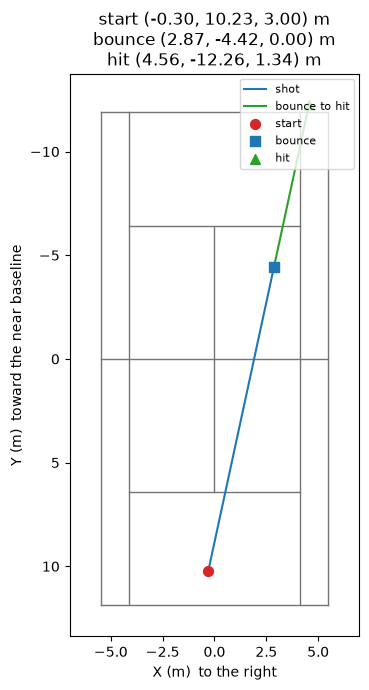

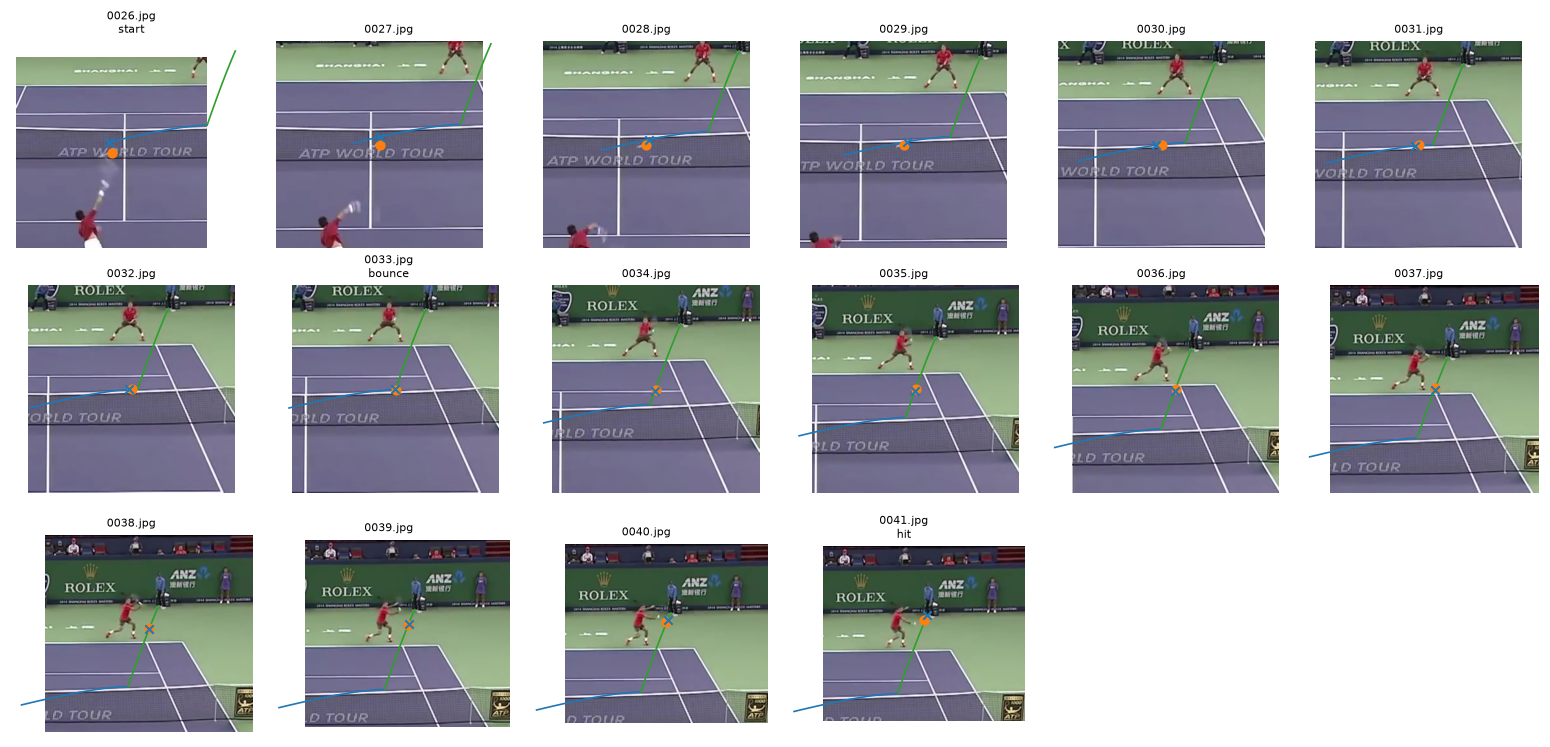

shot 2  0041.jpg → 0074.jpg
  start position  X    4.56 m   Y  -12.26 m   Z   1.34 m
  start velocity  vx   -9.44 m/s   vy   24.53 m/s   vz   4.39 m/s
  speed             59.6 mph
  bounce position X   -3.47 m   Y    8.60 m   Z   0.00 m
  bounce velocity in  vx   -5.74 m/s   vy   14.90 m/s   vz  -5.99 m/s
  bounce to hit   modeled through to the next hit
  apex height       2.18 m
  ball at net       2.03 m
  clearance       1.11 m
  launch angle       9.5 deg
  landing         ( -3.47,   8.60) m   8.60 m past the net   3.29 m inside the baseline   singles
  fit RMSE         19.38 px


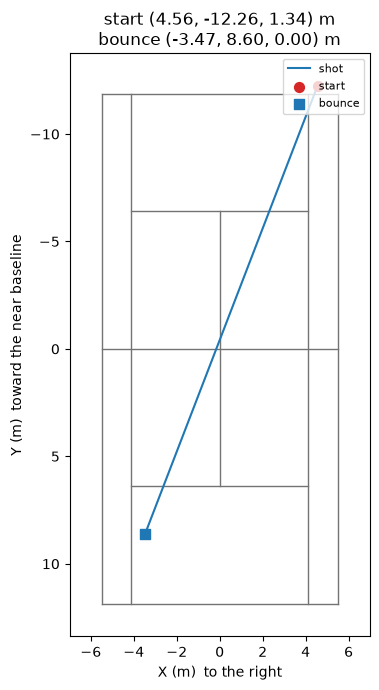

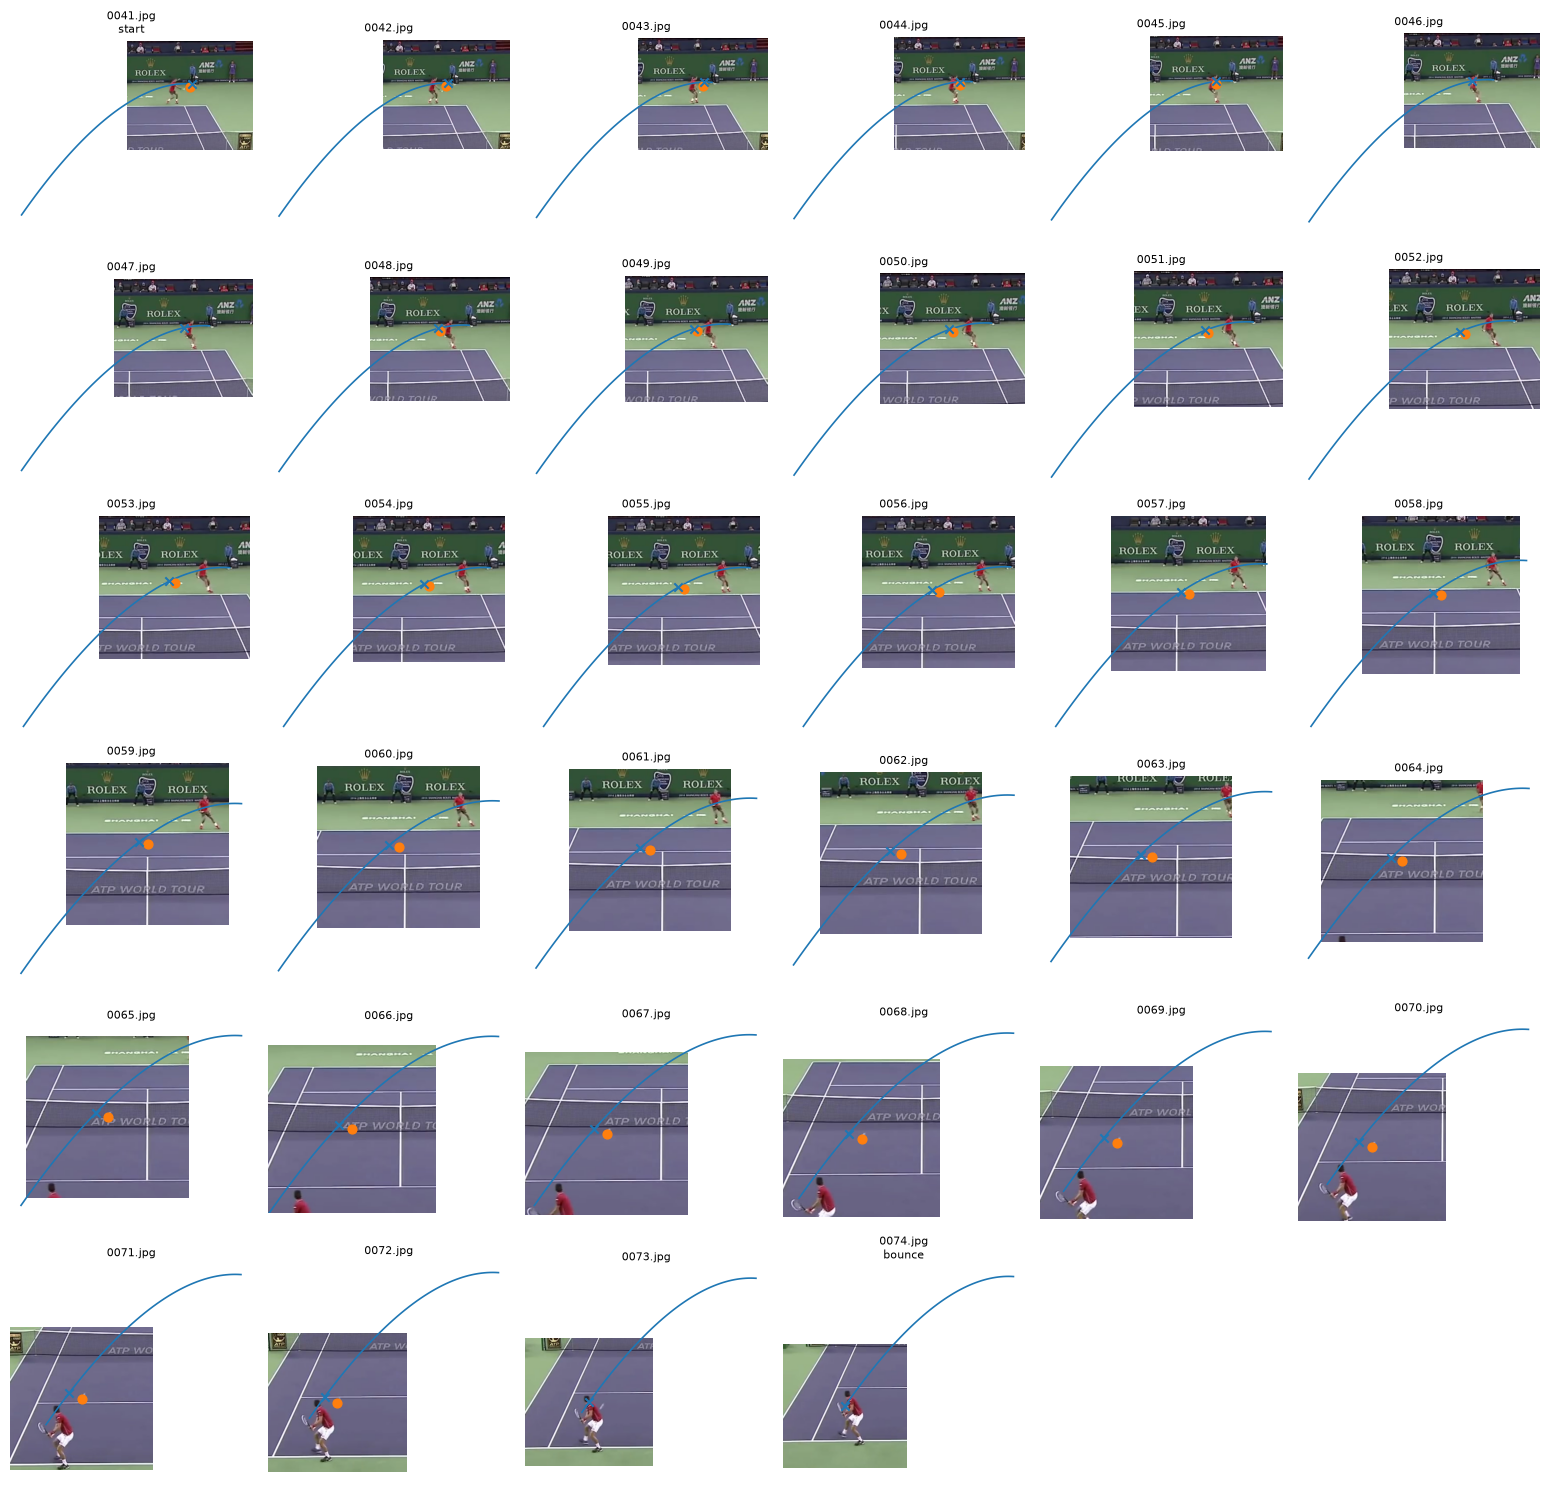

shot 3  0084.jpg → 0105.jpg
  start position  X   -2.86 m   Y    9.72 m   Z   2.00 m
  start velocity  vx   10.62 m/s   vy  -33.82 m/s   vz   0.16 m/s
  speed             79.3 mph
  bounce position X    3.07 m   Y   -9.16 m   Z   0.00 m
  bounce velocity in  vx    6.85 m/s   vy  -21.81 m/s   vz  -5.54 m/s
  bounce velocity out vx    5.35 m/s   vy  -17.03 m/s   vz   4.21 m/s
  bounce horizontal  78.1% kept   turned   0.0 deg
  bounce to hit   0105.jpg → 0114.jpg   RMSE  3.95 px
  hit position    X    4.75 m   Y  -14.48 m   Z   0.80 m
  hit velocity in vx    4.72 m/s   vy  -15.04 m/s   vz   0.64 m/s
  hit velocity out vx   -5.38 m/s   vy   52.07 m/s   vz   0.97 m/s
  apex height       2.00 m
  ball at net       1.57 m
  clearance       0.65 m
  launch angle       0.3 deg
  landing         (  3.07,  -9.16) m   9.16 m past the net   2.73 m inside the baseline   singles
  fit RMSE         14.89 px


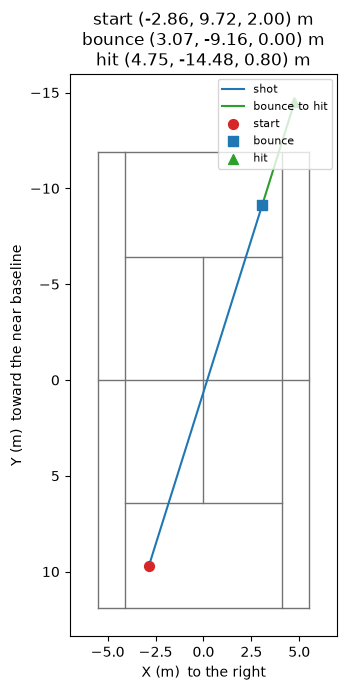

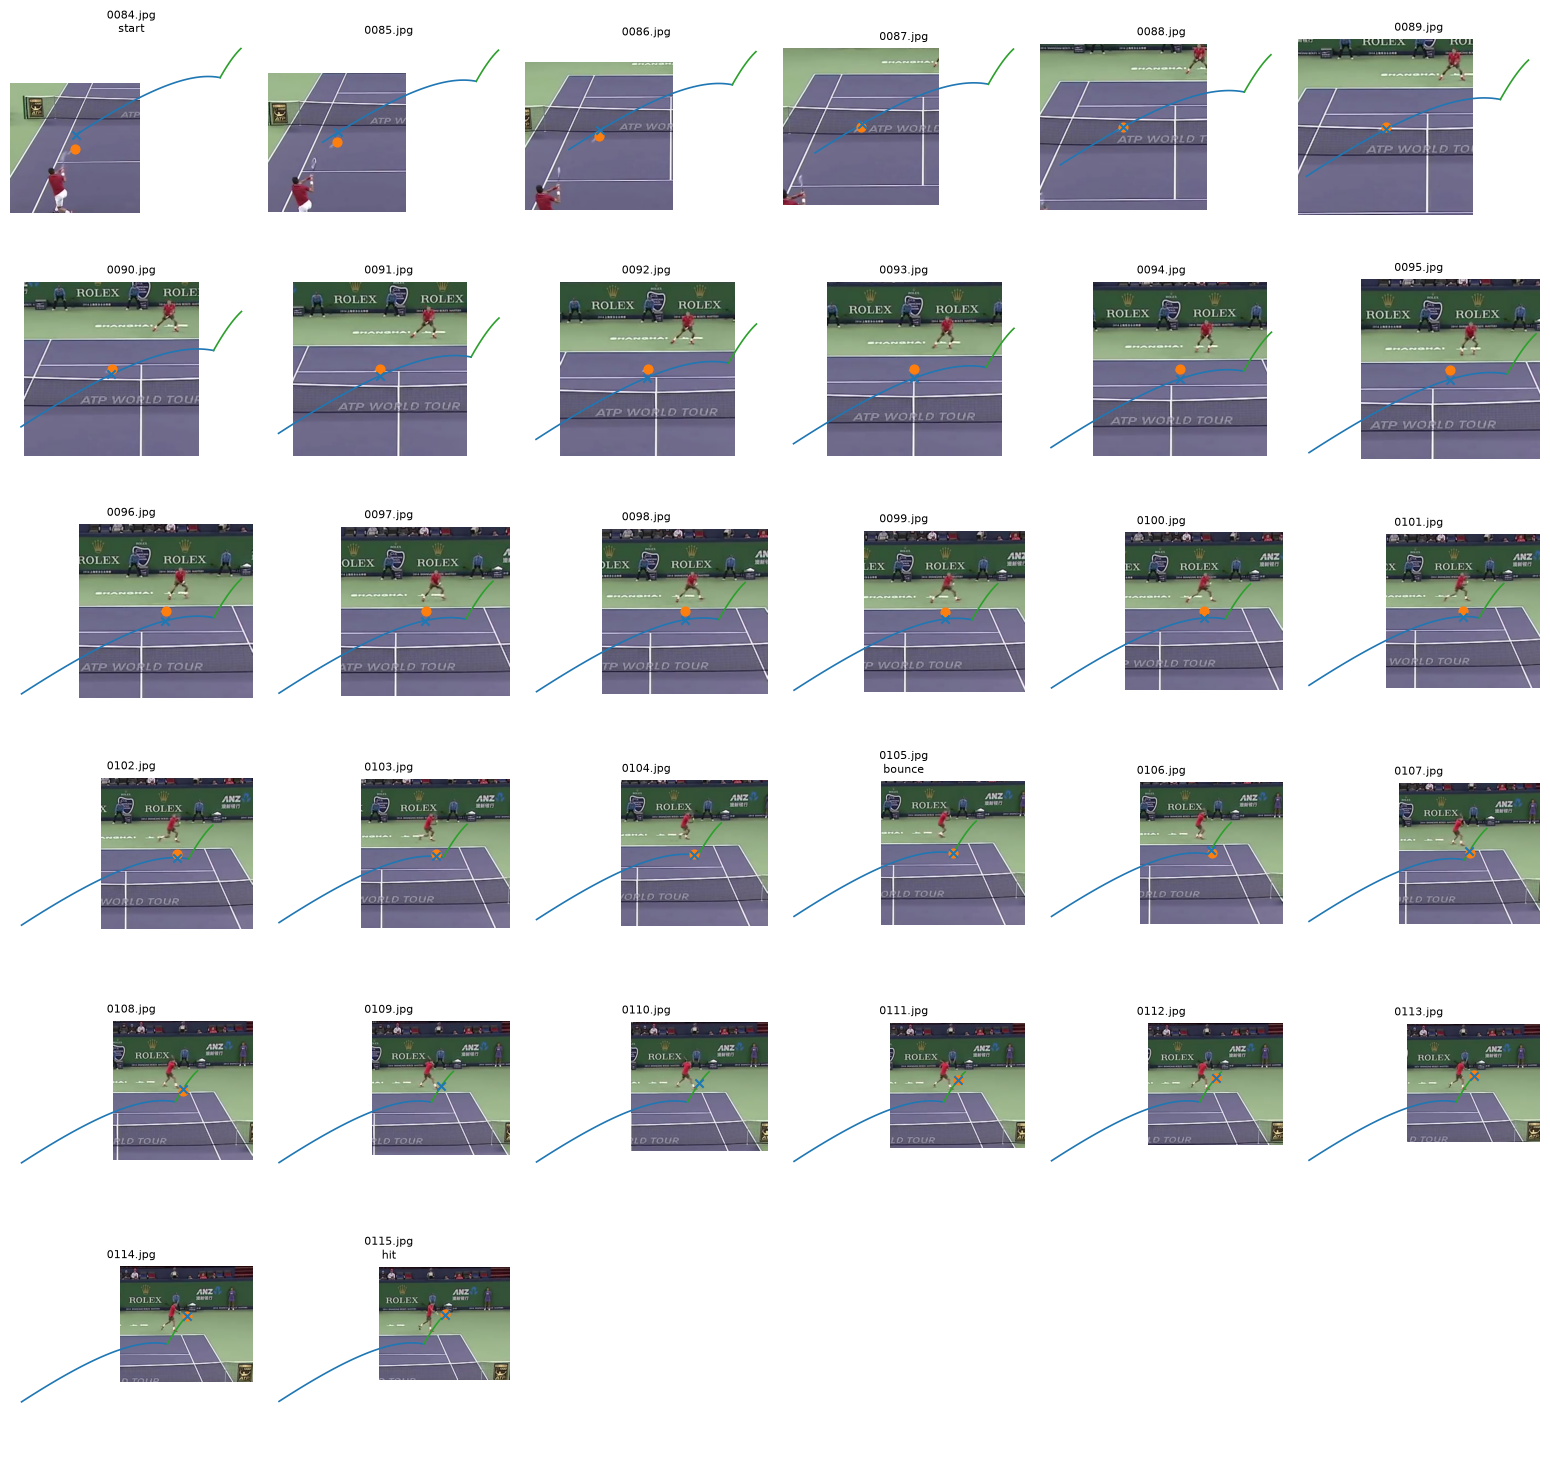

shot 4  0115.jpg → 0131.jpg
  start position  X    4.75 m   Y  -14.48 m   Z   0.80 m
  start velocity  vx   -5.38 m/s   vy   52.07 m/s   vz   0.97 m/s
  speed            117.1 mph
  bounce position X    2.51 m   Y    7.16 m   Z   0.00 m
  bounce velocity in  vx   -3.33 m/s   vy   32.24 m/s   vz  -3.63 m/s
  bounce velocity out vx   -2.67 m/s   vy   25.79 m/s   vz   5.52 m/s
  bounce horizontal  80.0% kept   turned   0.0 deg
  bounce to hit   0131.jpg → 0140.jpg   RMSE  4.85 px
  hit position    X    1.70 m   Y   15.02 m   Z   1.17 m
  hit velocity in vx   -2.24 m/s   vy   21.63 m/s   vz   1.62 m/s
  hit velocity out vx   -2.74 m/s   vy  -37.59 m/s   vz   2.18 m/s
  apex height       0.84 m
  ball at net       0.59 m
  clearance       -0.40 m
  launch angle       1.1 deg
  landing         (  2.51,   7.16) m   7.16 m past the net   4.72 m inside the baseline   singles
  fit RMSE         11.36 px


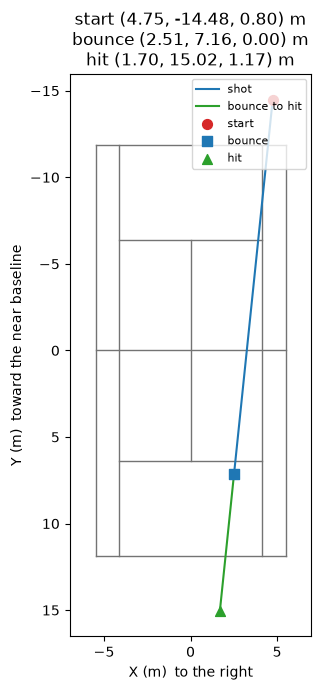

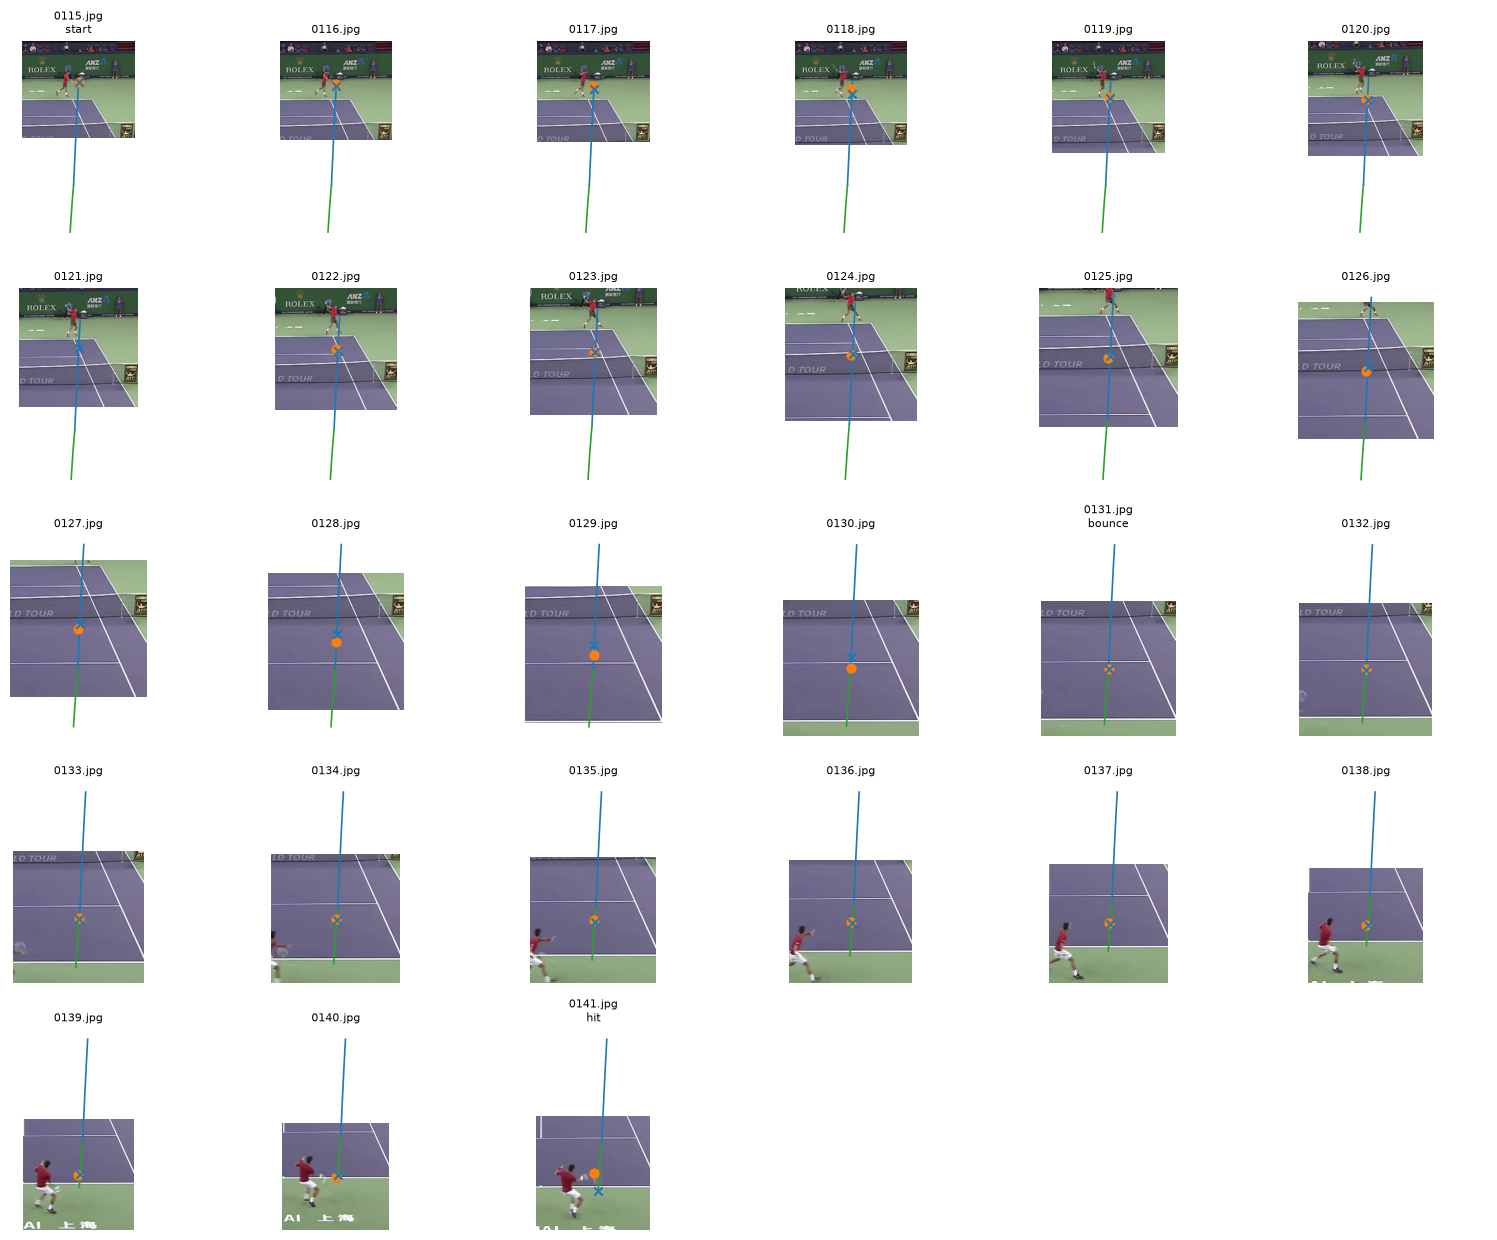

shot 5  0141.jpg → 0164.jpg
  start position  X    1.70 m   Y   15.02 m   Z   1.17 m
  start velocity  vx   -2.74 m/s   vy  -37.59 m/s   vz   2.18 m/s
  speed             84.5 mph
  bounce position X    0.07 m   Y   -7.28 m   Z  -0.00 m
  bounce velocity in  vx   -1.67 m/s   vy  -22.94 m/s   vz  -4.72 m/s
  bounce velocity out vx   -1.34 m/s   vy  -18.35 m/s   vz   4.33 m/s
  bounce horizontal  80.0% kept   turned   0.0 deg
  bounce to hit   0164.jpg → 0173.jpg   RMSE  3.17 px
  hit position    X   -0.34 m   Y  -13.01 m   Z   0.83 m
  hit velocity in vx   -1.18 m/s   vy  -16.15 m/s   vz   0.74 m/s
  hit velocity out vx    9.94 m/s   vy   47.32 m/s   vz   1.18 m/s
  apex height       1.39 m
  ball at net       1.05 m
  clearance       0.12 m
  launch angle       3.3 deg
  landing         (  0.07,  -7.28) m   7.28 m past the net   4.61 m inside the baseline   singles
  fit RMSE         43.20 px


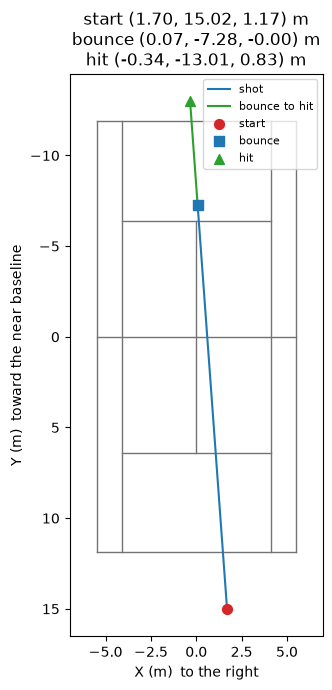

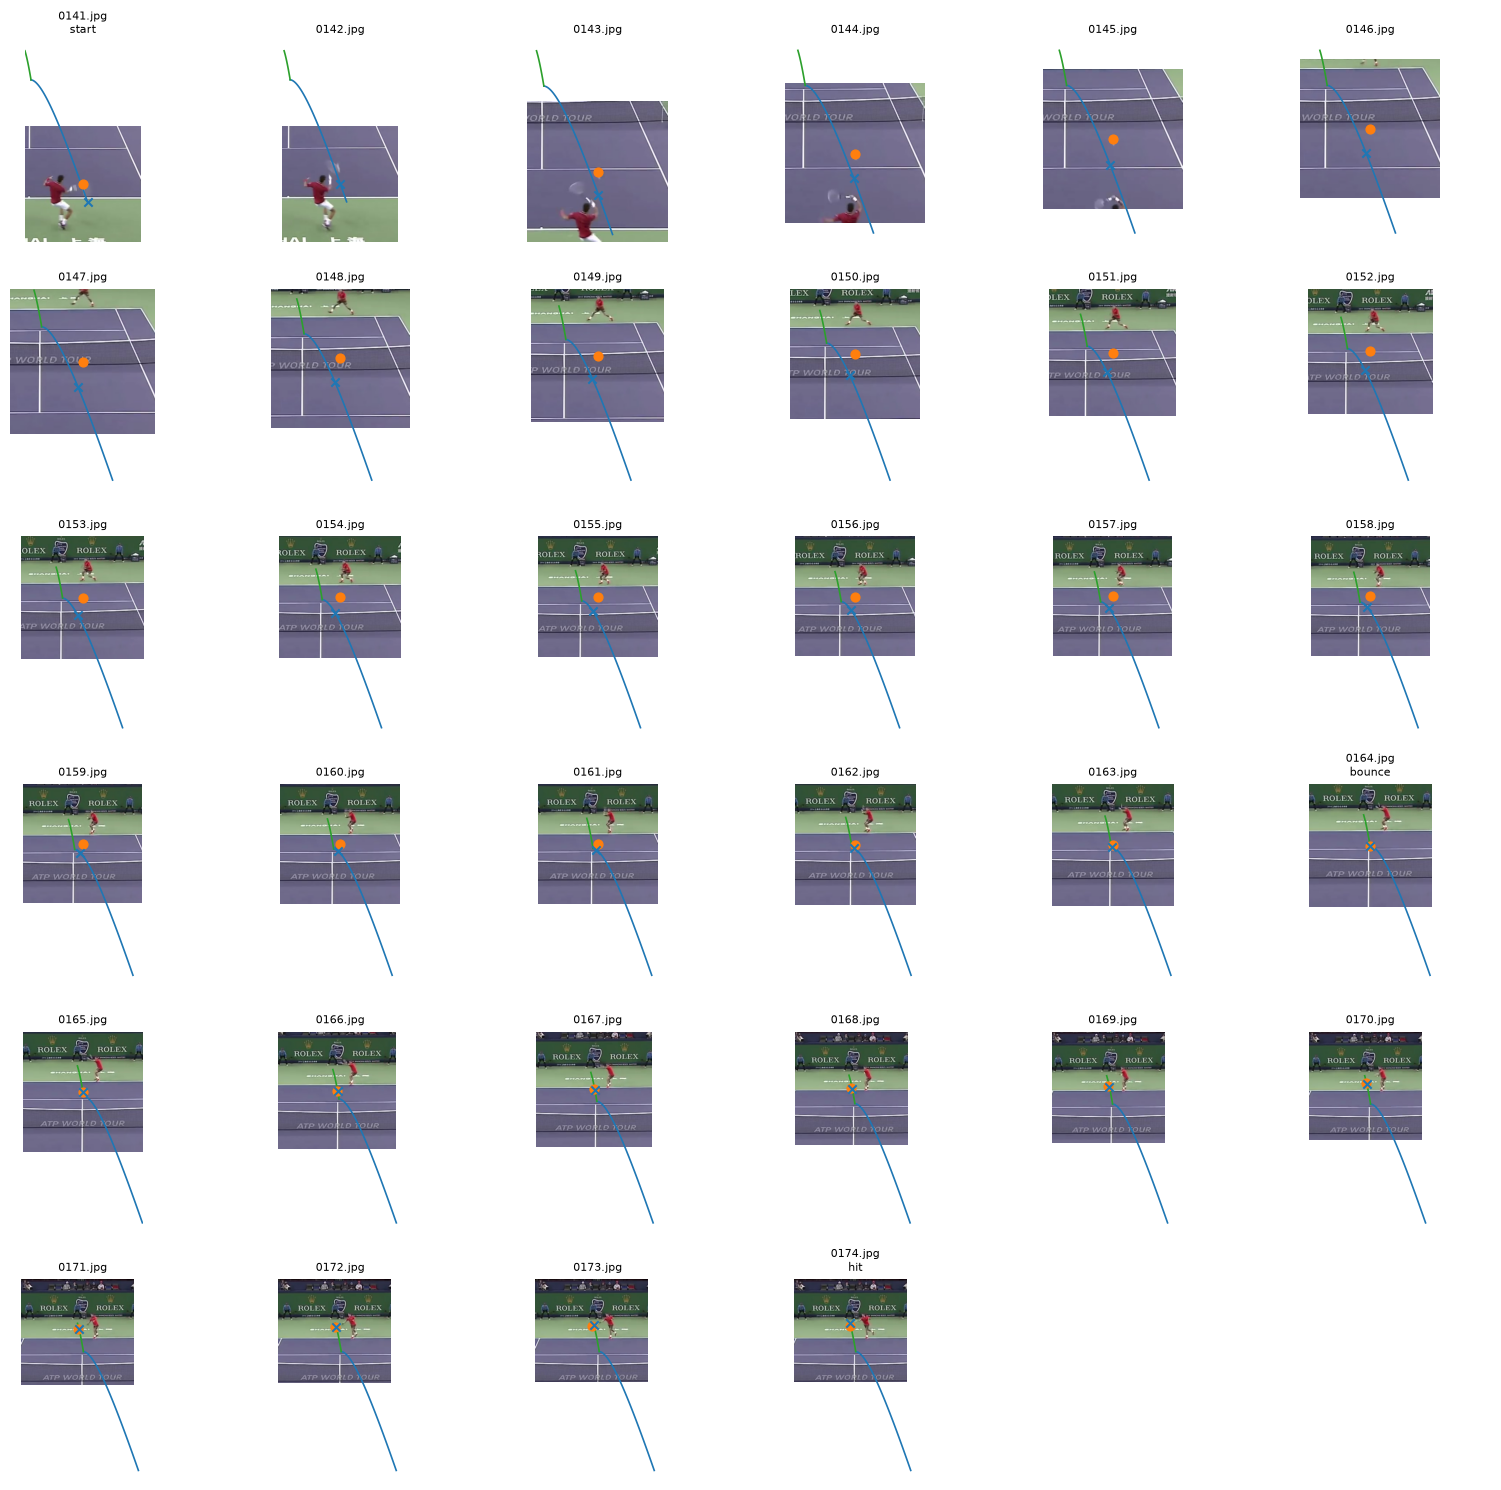

shot 6  0174.jpg → 0191.jpg
  start position  X   -0.34 m   Y  -13.01 m   Z   0.83 m
  start velocity  vx    9.94 m/s   vy   47.32 m/s   vz   1.18 m/s
  speed            108.2 mph
  bounce position X    4.06 m   Y    7.97 m   Z   0.00 m
  bounce velocity in  vx    6.19 m/s   vy   29.50 m/s   vz  -3.77 m/s
  bounce velocity out vx    4.42 m/s   vy   21.04 m/s   vz   5.15 m/s
  bounce horizontal  71.3% kept   turned   0.0 deg
  bounce to hit   0191.jpg → 0206.jpg   RMSE  9.83 px
  apex height       0.90 m
  ball at net       0.70 m
  clearance       -0.27 m
  launch angle       1.4 deg
  landing         (  4.06,   7.97) m   7.97 m past the net   3.91 m inside the baseline   singles
  fit RMSE         13.11 px


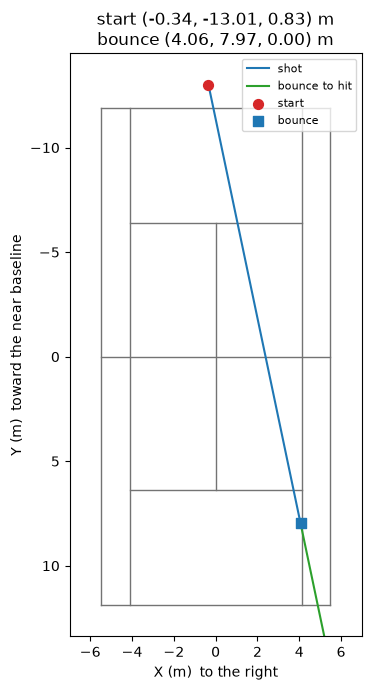

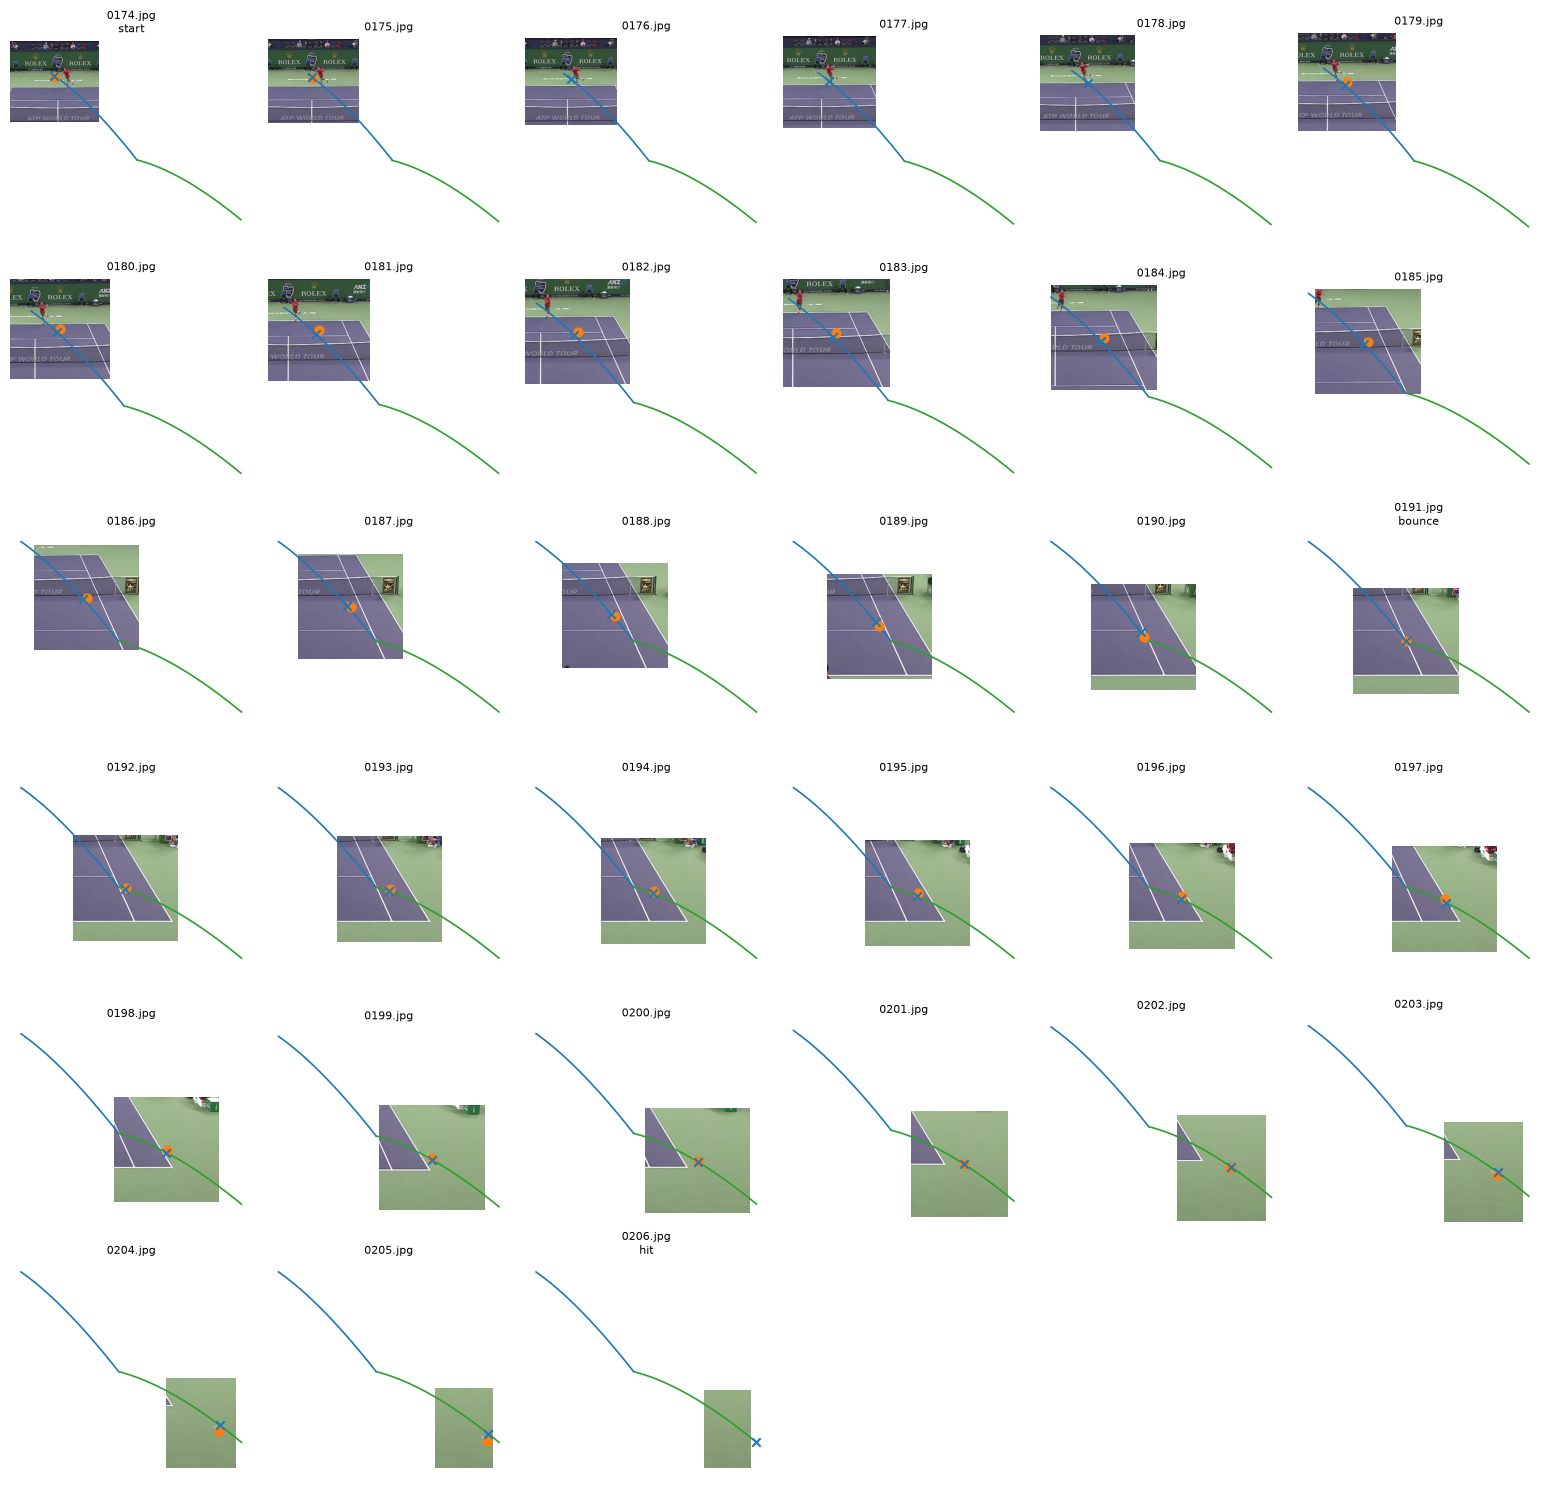

In [10]:
def clearance_line(metrics) -> str:
    if metrics.net_clearance_m is not None:
        return f"{metrics.net_clearance_m:.2f} m"
    if metrics.net_wide:
        return "wide of the posts"
    return "no crossing"


def past_line(metrics) -> str:
    distance = metrics.past_net_m
    if distance >= 0.0:
        return f"{distance:.2f} m past the net"
    return f"{-distance:.2f} m short of the net"


def margin_line(metrics) -> str:
    margin = metrics.baseline_margin_m
    if margin >= 0.0:
        return f"{margin:.2f} m inside the baseline"
    return f"{-margin:.2f} m past the baseline"


def read_bgr(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)
    if image.shape[1] != width or image.shape[0] != height:
        image = cv2.resize(image, (width, height), interpolation=cv2.INTER_AREA)
    return image


def ground_segments():
    found = []
    for start, end in segments():
        if abs(float(start[2])) > 1e-8 or abs(float(end[2])) > 1e-8:
            continue
        found.append((start[:2], end[:2]))
    return found


GROUND = ground_segments()
RADIUS = 160


def court_limits(points):
    pad = 1.5
    x0, x1 = -HALF_DOUBLES - pad, HALF_DOUBLES + pad
    y0, y1 = -HALF_LENGTH - pad, HALF_LENGTH + pad
    for point in points:
        if point is None or not np.isfinite(point).all():
            continue
        x0 = min(x0, float(point[0]) - pad)
        x1 = max(x1, float(point[0]) + pad)
        y0 = min(y0, float(point[1]) - pad)
        y1 = max(y1, float(point[1]) + pad)
    return max(x0, -25.0), min(x1, 25.0), max(y0, -30.0), min(y1, 30.0)


def draw_court(ax, shot_path, follow_path, start_xy, bounce_xy, hit_xy) -> None:
    for a, b in GROUND:
        ax.plot([a[0], b[0]], [a[1], b[1]], color="0.45", lw=1.0)
    finite = shot_path[np.isfinite(shot_path).all(axis=1)]
    if len(finite):
        ax.plot(finite[:, 0], finite[:, 1], color="C0", lw=1.5, label="shot")
    if follow_path is not None:
        finite = follow_path[np.isfinite(follow_path).all(axis=1)]
        if len(finite):
            ax.plot(finite[:, 0], finite[:, 1], color="C2", lw=1.5, label="bounce to hit")
    ax.scatter([start_xy[0]], [start_xy[1]], s=50, c="C3", zorder=3, label="start")
    ax.scatter(
        [bounce_xy[0]], [bounce_xy[1]], s=50, c="C0", marker="s", zorder=3, label="bounce"
    )
    points = [start_xy, bounce_xy]
    if hit_xy is not None:
        ax.scatter([hit_xy[0]], [hit_xy[1]], s=50, c="C2", marker="^", zorder=3, label="hit")
        points.append(hit_xy)
    x0, x1, y0, y1 = court_limits(points)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("X (m)  to the right")
    ax.set_ylabel("Y (m)  toward the near baseline")
    ax.legend(loc="upper right", fontsize=8)


def project_curve(fit, t0, t1, *, follow=False):
    times = np.linspace(float(t0), float(t1), 50)
    return camera.project(fit.path(times, follow=follow))


def draw_frames(flight, fit, follow, t_bounce, t_hit=None, hit_frame=None) -> None:
    if fit.follow_theta is not None and hit_frame is not None:
        end = hit_frame
    elif fit.follow_theta is not None and follow is not None:
        end = follow.end
    else:
        end = flight.end
    ids = np.arange(flight.start, end + 1)
    shot_curve = project_curve(fit, 0.0, t_bounce)
    follow_curve = None
    if fit.follow_theta is not None:
        if t_hit is not None:
            t1 = t_hit
        elif follow is not None:
            t1 = (follow.end - follow.start) / FPS
        else:
            t1 = None
        if t1 is not None and t1 > 0:
            follow_curve = project_curve(fit, 0.0, t1, follow=True)
    cols = 6
    rows = int(np.ceil(len(ids) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, frame_i in zip(axes, ids):
        image = cv2.cvtColor(read_bgr(frames[frame_i]["path"]), cv2.COLOR_BGR2RGB)
        point = meas[frame_i]
        if frame_i <= flight.end:
            tt = (frame_i - flight.start) / FPS
            pred = camera.project(fit.path(np.array([tt])))[0]
        elif fit.follow_theta is not None:
            tt = (frame_i - flight.end) / FPS
            pred = camera.project(fit.path(np.array([tt]), follow=True))[0]
        else:
            pred = np.full(2, np.nan)
        anchor = point if np.isfinite(point).all() else pred
        if np.isfinite(anchor).all():
            x, y = int(round(float(anchor[0]))), int(round(float(anchor[1])))
            x0, x1 = max(0, x - RADIUS), min(image.shape[1], x + RADIUS)
            y0, y1 = max(0, y - RADIUS), min(image.shape[0], y + RADIUS)
            ax.imshow(image[y0:y1, x0:x1])
            ax.plot(shot_curve[:, 0] - x0, shot_curve[:, 1] - y0, color="C0", lw=1.2)
            if follow_curve is not None:
                ax.plot(follow_curve[:, 0] - x0, follow_curve[:, 1] - y0, color="C2", lw=1.2)
            if np.isfinite(point).all():
                ax.scatter([point[0] - x0], [point[1] - y0], s=40, c="C1", zorder=3)
            if np.isfinite(pred).all():
                ax.scatter([pred[0] - x0], [pred[1] - y0], s=36, c="C0", marker="x", zorder=4)
        else:
            ax.imshow(image)
        label = frames[frame_i]["file"]
        if frame_i == flight.start:
            label = f"{label}\nstart"
        elif hit_frame is not None and frame_i == hit_frame:
            label = f"{label}\nhit"
        elif frame_i == flight.end and flight.ends_on_bounce:
            label = f"{label}\nbounce"
        elif frame_i == flight.end:
            label = f"{label}\nstop"
        ax.set_title(label, fontsize=8)
        ax.set_axis_off()
    for ax in axes[len(ids) :]:
        ax.set_axis_off()
    fig.tight_layout()
    plt.show()


if not fitted:
    print("no shots")
else:
    for i, item in enumerate(fitted, start=1):
        flight = item["flight"]
        fit = item["fit"]
        metrics = item["metrics"]
        follow = item["follow"]
        t_bounce = item["t_bounce"]
        t_hit = item["t_hit"]
        x0, y0, z0, vx, vy, vz = (float(v) for v in fit.theta)
        bounce_pos, bounce_vel = fit.integrate(np.array([t_bounce]))
        bounce = bounce_pos[0]
        incoming = bounce_vel[0]
        span = f"{frames[flight.start]['file']} → {frames[flight.end]['file']}"
        print(f"shot {i}  {span}")
        print(f"  start position  X {x0:7.2f} m   Y {y0:7.2f} m   Z {z0:6.2f} m")
        print(f"  start velocity  vx {vx:7.2f} m/s   vy {vy:7.2f} m/s   vz {vz:6.2f} m/s")
        print(f"  speed           {metrics.speed_mph:6.1f} mph")
        print(
            f"  bounce position X {bounce[0]:7.2f} m   Y {bounce[1]:7.2f} m   Z {bounce[2]:6.2f} m"
        )
        print(
            f"  bounce velocity in  vx {incoming[0]:7.2f} m/s   vy {incoming[1]:7.2f} m/s"
            f"   vz {incoming[2]:6.2f} m/s"
        )
        hit = fit.hit_xyz
        follow_path = None
        if fit.follow_theta is not None:
            fx, fy, fz, fvx, fvy, fvz = (float(v) for v in fit.follow_theta)
            print(
                f"  bounce velocity out vx {fvx:7.2f} m/s   vy {fvy:7.2f} m/s   vz {fvz:6.2f} m/s"
            )
            speed_in = float(np.hypot(incoming[0], incoming[1]))
            speed_out = float(np.hypot(fvx, fvy))
            kept = speed_out / speed_in if speed_in > 1e-3 else float("nan")
            turn = float(np.degrees(np.arctan2(
                incoming[0] * fvy - incoming[1] * fvx,
                incoming[0] * fvx + incoming[1] * fvy,
            )))
            print(f"  bounce horizontal {kept * 100:5.1f}% kept   turned {turn:5.1f} deg")
            if t_hit is not None:
                t1 = t_hit
            elif follow is not None:
                t1 = (follow.end - follow.start) / FPS
            else:
                t1 = None
            if t1 is not None and t1 > 0:
                follow_path = fit.path(np.linspace(0.0, t1, 40), follow=True)
        if follow is not None and fit.follow_rmse_px is not None:
            follow_span = f"{frames[follow.start]['file']} → {frames[follow.end]['file']}"
            print(f"  bounce to hit   {follow_span}   RMSE {fit.follow_rmse_px:5.2f} px")
        elif t_hit is not None:
            print("  bounce to hit   modeled through to the next hit")
        else:
            print("  bounce to hit   no track")
        if hit is not None:
            hv = fit.hit_velocity
            print(f"  hit position    X {hit[0]:7.2f} m   Y {hit[1]:7.2f} m   Z {hit[2]:6.2f} m")
            print(
                f"  hit velocity in vx {hv[0]:7.2f} m/s   vy {hv[1]:7.2f} m/s   vz {hv[2]:6.2f} m/s"
            )
            if t_hit is not None and i < len(fitted):
                out = fitted[i]["fit"].theta
                print(
                    f"  hit velocity out vx {out[3]:7.2f} m/s   vy {out[4]:7.2f} m/s"
                    f"   vz {out[5]:6.2f} m/s"
                )
        print(f"  apex height     {metrics.apex_height_m:6.2f} m")
        if metrics.net_ball_height_m is None:
            print("  ball at net     —")
        else:
            print(f"  ball at net     {metrics.net_ball_height_m:6.2f} m")
        print(f"  clearance       {clearance_line(metrics)}")
        print(f"  launch angle    {metrics.launch_angle_deg:6.1f} deg")
        landing = metrics.landing_xyz
        where = f"{past_line(metrics)}   {metrics.landing}"
        if metrics.landing != "short":
            where = f"{past_line(metrics)}   {margin_line(metrics)}   {metrics.landing}"
        print(f"  landing         ({landing[0]:6.2f}, {landing[1]:6.2f}) m   {where}")
        print(f"  fit RMSE        {fit.rmse_px:6.2f} px")

        shot_path = fit.path(np.linspace(0.0, t_bounce, 60))
        fig, ax = plt.subplots(figsize=(6, 7))
        draw_court(
            ax,
            shot_path,
            follow_path,
            fit.theta[:2],
            bounce[:2],
            None if hit is None else hit[:2],
        )
        title = f"start ({x0:.2f}, {y0:.2f}, {z0:.2f}) m\nbounce ({bounce[0]:.2f}, {bounce[1]:.2f}, {bounce[2]:.2f}) m"
        if hit is not None:
            title += f"\nhit ({hit[0]:.2f}, {hit[1]:.2f}, {hit[2]:.2f}) m"
        ax.set_title(title)
        fig.tight_layout()
        plt.show()
        hit_frame = None
        if t_hit is not None:
            hit_frame = int(round(flight.end + t_hit * FPS))
        elif follow is not None:
            hit_frame = follow.end
        draw_frames(flight, fit, follow, t_bounce, t_hit=t_hit, hit_frame=hit_frame)
